In [2]:
pip install kagglehub

In [5]:

import os
import zipfile

ZIP_PATH = "/content/archive (3).zip"
EXTRACT_DIR = "/content/lung_dataset"

assert os.path.exists(ZIP_PATH), (
    "ZIP not found. Check the filename in the Colab Files panel."
)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(EXTRACT_DIR)

print("Dataset extracted successfully!")
print("Location:", EXTRACT_DIR)

Dataset extracted successfully!
Location: /content/lung_dataset


In [6]:

import os
import pandas as pd

IMAGE_EXTS = (".jpg", ".jpeg", ".png", ".bmp")
CLASS_NAMES = ["Bengin cases", "Malignant cases", "Normal cases"]

class_dirs = {}

for root, dirs, files in os.walk(EXTRACT_DIR):
    for folder in dirs:
        if folder in CLASS_NAMES:
            class_dirs[folder] = os.path.join(root, folder)

print("Found class folders:", class_dirs.keys())

assert len(class_dirs) == 3, (
    "Could not find all 3 classes. Check the printed folder structure."
)

records = []

for label, folder_path in class_dirs.items():
    for root, dirs, files in os.walk(folder_path):
        for filename in files:
            if filename.lower().endswith(IMAGE_EXTS):
                records.append({
                    "filepath": os.path.join(root, filename),
                    "label": label
                })

df = pd.DataFrame(records)

print("\nImage counts:")
print(df["label"].value_counts())
print("\nTotal images:", len(df))
df.head()

Found class folders: dict_keys(['Malignant cases', 'Normal cases', 'Bengin cases'])

Image counts:
label
Malignant cases    561
Normal cases       416
Bengin cases       120
Name: count, dtype: int64

Total images: 1097


,filepath,label
0,/content/lung_dataset/The IQ-OTHNCCD lung canc...,Malignant cases
1,/content/lung_dataset/The IQ-OTHNCCD lung canc...,Malignant cases
2,/content/lung_dataset/The IQ-OTHNCCD lung canc...,Malignant cases
3,/content/lung_dataset/The IQ-OTHNCCD lung canc...,Malignant cases
4,/content/lung_dataset/The IQ-OTHNCCD lung canc...,Malignant cases


In [7]:

from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

Training images: 767
Validation images: 165
Testing images: 165


In [8]:

import os

for root, dirs, files in os.walk(EXTRACT_DIR):
    depth = root.replace(EXTRACT_DIR, "").count(os.sep)

    if depth <= 3:
        print("  " * depth + os.path.basename(root) + "/")
        for f in files[:3]:
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
                print("  " * (depth + 1) + f)

ValueError: The `class_names` passed did not match the names of the subdirectories of the target directory. Expected: ['Test cases', 'The IQ-OTHNCCD lung cancer dataset'] (or a subset of it), but received: class_names=['Bengin cases', 'Malignant cases', 'Normal cases']

In [9]:

import os

for root, dirs, files in os.walk(EXTRACT_DIR):
    depth = root.replace(EXTRACT_DIR, "").count(os.sep)

    if depth <= 3:
        print("  " * depth + os.path.basename(root) + "/")
        for f in files[:3]:
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
                print("  " * (depth + 1) + f)

lung_dataset/
  Test cases/
    000058_06_02_223.png
    000188_03_01_146.png
    000027_04_01_119.png
  The IQ-OTHNCCD lung cancer dataset/
    The IQ-OTHNCCD lung cancer dataset/
      Malignant cases/
        Malignant case (415).jpg
        Malignant case (537).jpg
        Malignant case (559).jpg
      Normal cases/
        Normal case (360).jpg
        Normal case (311).jpg
        Normal case (369).jpg
      Bengin cases/
        Bengin case (88).jpg
        Bengin case (55).jpg
        Bengin case (109).jpg


In [10]:

import os

CLASS_NAMES = ["Bengin cases", "Malignant cases", "Normal cases"]

found = {}

for root, dirs, files in os.walk(EXTRACT_DIR):
    for folder in dirs:
        if folder in CLASS_NAMES:
            found[folder] = os.path.join(root, folder)

print("Found classes:")
for name, path in found.items():
    print(name, "->", path)

assert len(found) == 3, (
    "Not all three class folders were found. "
    "Run Step 1 and share its output."
)

# All three class folders should have the same parent
parents = {os.path.dirname(p) for p in found.values()}
assert len(parents) == 1, f"Class folders have different parents: {parents}"

DATA_DIR = parents.pop()
print("\nCorrect dataset directory:", DATA_DIR)

Found classes:
Malignant cases -> /content/lung_dataset/The IQ-OTHNCCD lung cancer dataset/The IQ-OTHNCCD lung cancer dataset/Malignant cases
Normal cases -> /content/lung_dataset/The IQ-OTHNCCD lung cancer dataset/The IQ-OTHNCCD lung cancer dataset/Normal cases
Bengin cases -> /content/lung_dataset/The IQ-OTHNCCD lung cancer dataset/The IQ-OTHNCCD lung cancer dataset/Bengin cases

Correct dataset directory: /content/lung_dataset/The IQ-OTHNCCD lung cancer dataset/The IQ-OTHNCCD lung cancer dataset


In [11]:

import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    labels="inferred",
    label_mode="categorical",
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.30,
    subset="training",
    seed=SEED
)

print("Training dataset loaded successfully!")
print("Classes:", train_ds.class_names if hasattr(train_ds, "class_names") else CLASS_NAMES)

Found 1097 files belonging to 3 classes.
Using 768 files for training.
Training dataset loaded successfully!
Classes: ['Bengin cases', 'Malignant cases', 'Normal cases']


In [12]:

import pandas as pd
from sklearn.model_selection import train_test_split
import tensorflow as tf
import os

# Image paths collect karo
records = []

for label in CLASS_NAMES:
    folder = os.path.join(DATA_DIR, label)

    for root, dirs, files in os.walk(folder):
        for file in files:
            if file.lower().endswith(
                (".jpg", ".jpeg", ".png", ".bmp")
            ):
                records.append({
                    "filepath": os.path.join(root, file),
                    "label": label
                })

df = pd.DataFrame(records)

print("Total images:", len(df))
print(df["label"].value_counts())

# 70% training, 15% validation, 15% testing
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

print("\nTraining:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Total images: 1097
label
Malignant cases    561
Normal cases       416
Bengin cases       120
Name: count, dtype: int64

Training: 767
Validation: 165
Testing: 165


In [13]:

import numpy as np
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

IMG_SIZE = (224, 224)
BATCH_SIZE = 16

label_map = {
    name: i for i, name in enumerate(CLASS_NAMES)
}

def make_dataset(frame, training=False):
    paths = frame["filepath"].values
    labels = frame["label"].map(label_map).values

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    def load_image(path, label):
        image = tf.io.read_file(path)
        image = tf.io.decode_image(
            image,
            channels=3,
            expand_animations=False
        )
        image.set_shape([None, None, 3])
        image = tf.image.resize(image, IMG_SIZE)
        image = preprocess_input(image)
        label = tf.one_hot(label, len(CLASS_NAMES))
        return image, label

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if training:
        ds = ds.shuffle(500, seed=42)

    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

print("Training, validation and test datasets ready!")

Training, validation and test datasets ready!


In [14]:

from tensorflow.keras import layers, Model

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Pretrained layers freeze karo
base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))

x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.30)(x)

outputs = layers.Dense(
    len(CLASS_NAMES),
    activation="softmax"
)(x)

model = Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [15]:

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "/content/best_lung_model.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10
48/48 ━━━━━━━━━━━━━━━━━━━━ 26s 426ms/step - accuracy: 0.7223 - loss: 0.6464 - val_accuracy: 0.8909 - val_loss: 0.3920
Epoch 2/10
48/48 ━━━━━━━━━━━━━━━━━━━━ 20s 397ms/step - accuracy: 0.8370 - loss: 0.4145 - val_accuracy: 0.8909 - val_loss: 0.3030
Epoch 3/10
48/48 ━━━━━━━━━━━━━━━━━━━━ 22s 428ms/step - accuracy: 0.8722 - loss: 0.3272 - val_accuracy: 0.8909 - val_loss: 0.2812
Epoch 4/10
48/48 ━━━━━━━━━━━━━━━━━━━━ 26s 510ms/step - accuracy: 0.8722 - loss: 0.3096 - val_accuracy: 0.8909 - val_loss: 0.2544
Epoch 5/10
48/48 ━━━━━━━━━━━━━━━━━━━━ 22s 450ms/step - accuracy: 0.8748 - loss: 0.2736 - val_accuracy: 0.9212 - val_loss: 0.2227
Epoch 6/10
48/48 ━━━━━━━━━━━━━━━━━━━━ 41s 456ms/step - accuracy: 0.9113 - loss: 0.2263 - val_accuracy: 0.9152 - val_loss: 0.2362
Epoch 7/10
48/48 ━━━━━━━━━━━━━━━━━━━━ 40s 449ms/step - accuracy: 0.9283 - loss: 0.2037 - val_accuracy: 0.9273 - val_loss: 0.1979
Epoch 8/10
48/48 ━━━━━━━━━━━━━━━━━━━━ 22s 433ms/step - accuracy: 0.9192 - loss: 0.1968 - val_accu

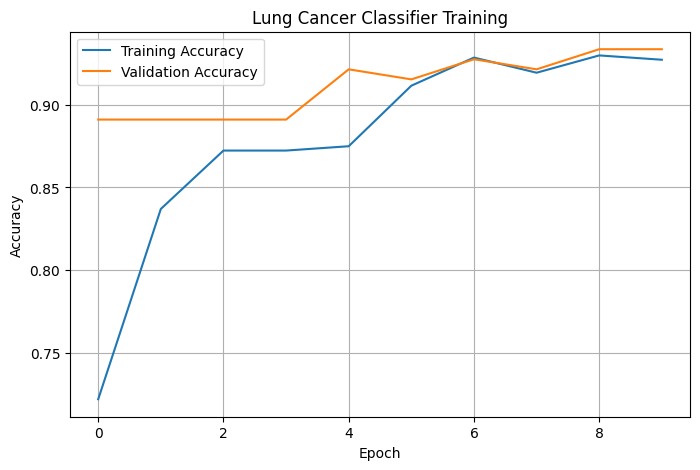

In [16]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Lung Cancer Classifier Training")
plt.legend()
plt.grid(True)
plt.show()

In [17]:

from sklearn.metrics import classification_report, confusion_matrix

test_loss, test_accuracy = model.evaluate(test_ds)

print(f"\nTest Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

y_true = np.concatenate([
    np.argmax(labels.numpy(), axis=1)
    for images, labels in test_ds
])

y_prob = model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

11/11 ━━━━━━━━━━━━━━━━━━━━ 9s 845ms/step - accuracy: 0.9212 - loss: 0.2026

Test Accuracy: 92.12%
Test Loss: 0.2026
11/11 ━━━━━━━━━━━━━━━━━━━━ 14s 896ms/step

Classification Report:
                 precision    recall  f1-score   support

   Bengin cases       0.73      0.44      0.55        18
Malignant cases       1.00      1.00      1.00        85
   Normal cases       0.86      0.95      0.90        62

       accuracy                           0.92       165
      macro avg       0.86      0.80      0.82       165
   weighted avg       0.92      0.92      0.91       165


Confusion Matrix:
[[ 8  0 10]
 [ 0 85  0]
 [ 3  0 59]]


Saving ChatGPT Image Oct 13, 2026, 03_00_16 PM.png to ChatGPT Image Oct 13, 2026, 03_00_16 PM.png


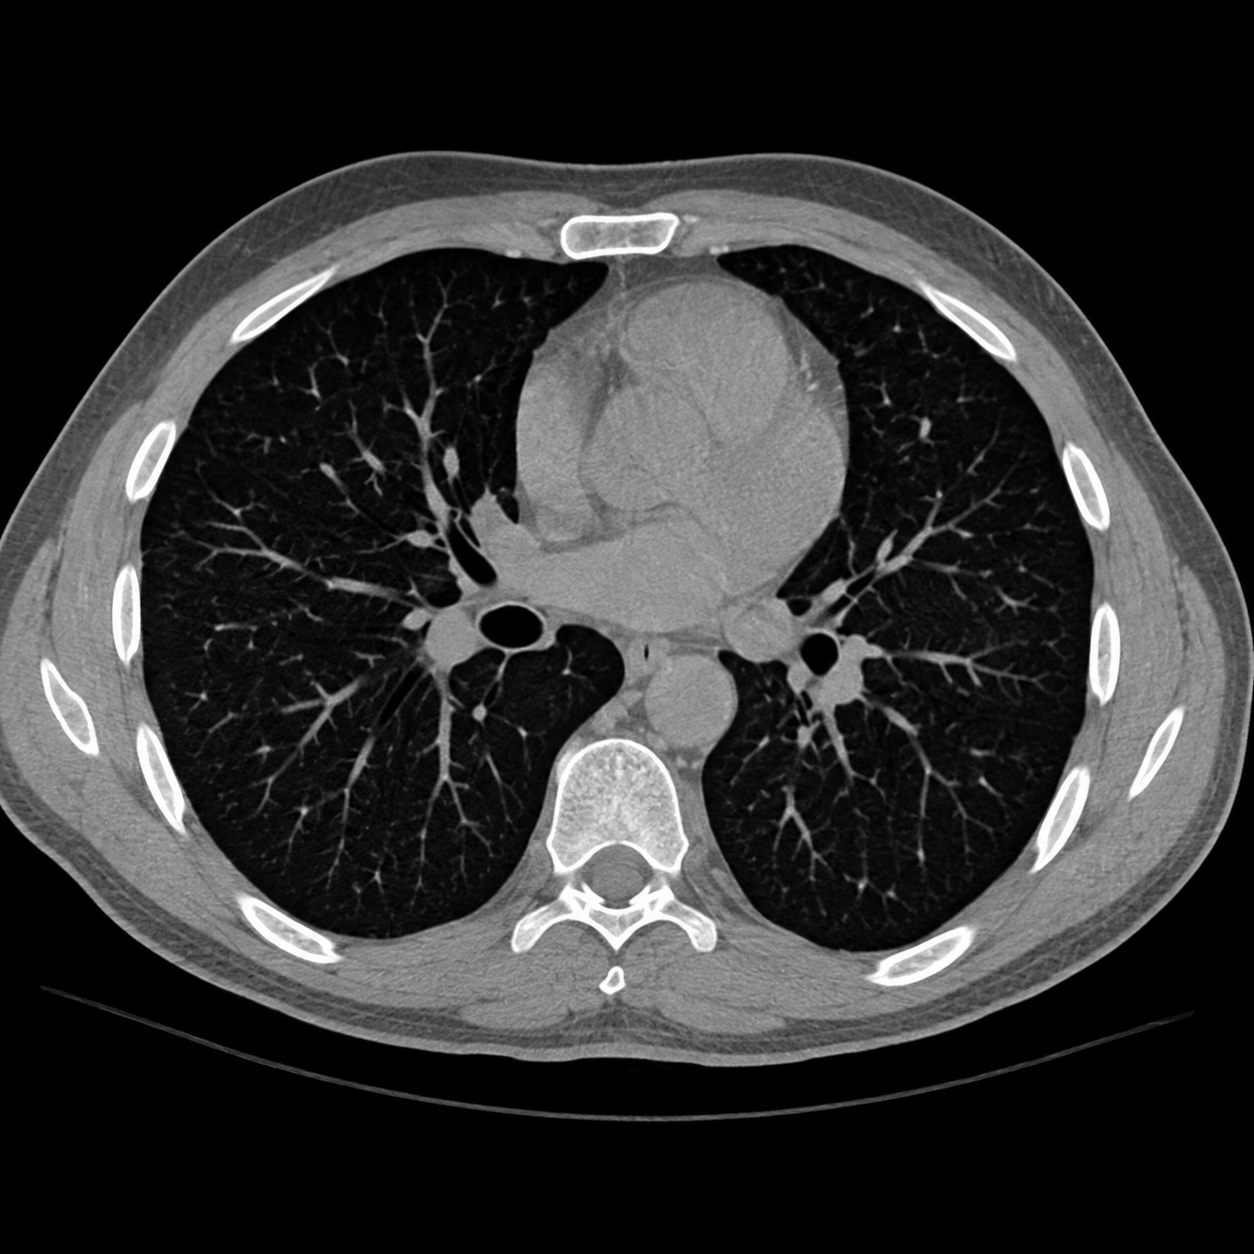


Model output: Malignant cases

Class scores:
Bengin cases: 1.82%
Malignant cases: 95.36%
Normal cases: 2.82%


In [18]:

from google.colab import files
from PIL import Image
import numpy as np

uploaded = files.upload()

for filename in uploaded:
    img = Image.open(filename).convert("RGB")
    display(img)

    img = img.resize(IMG_SIZE)

    arr = np.array(img, dtype=np.float32)
    arr = preprocess_input(arr)
    arr = np.expand_dims(arr, axis=0)

    predictions = model.predict(arr, verbose=0)[0]

    predicted_class = CLASS_NAMES[np.argmax(predictions)]

    print("\nModel output:", predicted_class)
    print("\nClass scores:")

    for name, score in zip(CLASS_NAMES, predictions):
        print(f"{name}: {score * 100:.2f}%")

In [19]:

from google.colab import files

model.save("/content/lung_cancer_classifier.keras")

files.download("/content/lung_cancer_classifier.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>